# 01. Klasifikasi URL MURL — SVM linear dengan TF-IDF karakter

Tujuan notebook ini adalah melatih dan mengevaluasi satu metode pada satu preprocessing. Semua notebook memakai dataset, split domain/IP dan prosedur evaluasi, dan format hasil yang sama. **Perbedaannya hanya metode training beserta parameter metodenya.**

Alur: lingkungan → preprocessing (audit/pembersihan data → split dan audit host → transformasi fitur) → metode training → training final → validation → test → interpretasi. Notebook ini mandiri; untuk distribusi cukup bawa notebook ini dan `Malicious URL Detection.csv`. Semua fungsi serta data pendukung split ada di dalam notebook; tidak ada impor fungsi dari file Python lokal. Jalankan satu per satu agar memori tetap terkendali. Hanya hasil model ini yang ditampilkan; perbandingan antarmodel disiapkan terpisah pada pekerjaan berikutnya.


## 1. Persiapan lingkungan

Gunakan kernel **Python (.venv MURL)** dan jalankan sel dari atas. Sel awal hanya mempersiapkan lingkungan; parameter model baru ditetapkan pada bagian metode, setelah preprocessing selesai. Blok persiapan dan seluruh tahap preprocessing sama persis pada seluruh notebook dengan representasi yang sama.


**Persiapan saat mendistribusikan notebook:** letakkan notebook dan `Malicious URL Detection.csv` dalam satu folder. Semua fungsi, frozen split dan Public Suffix List sudah ada di notebook; file Python lokal tidak diperlukan. Jika environment belum tersedia, jalankan dari terminal di folder tersebut:

```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install numpy==2.4.6 pandas==3.0.6 scipy==1.17.1 scikit-learn==1.9.1 matplotlib==3.11.2 tldextract==5.3.0 idna==3.20 ipykernel==7.3.0 jupyterlab==4.6.4
.venv/bin/python -m ipykernel install --user --name murl-venv --display-name "Python (.venv MURL)"
.venv/bin/jupyter lab
```

Jika `.venv` dibuat dengan uv dan belum memuat pip, gunakan `uv pip install --python .venv/bin/python` dengan daftar paket yang sama untuk langkah instalasi. Pilih kernel **Python (.venv MURL)** sebelum menjalankan sel.


In [1]:
from pathlib import Path
import sys
import importlib.metadata
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert Path(sys.prefix).resolve() == (ROOT / ".venv").resolve(), "Pilih kernel Python (.venv MURL), lalu restart kernel."
print("Interpreter aktif:", sys.executable)
versi = {nama: importlib.metadata.version(nama) for nama in
         ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "ipykernel", "tldextract", "idna"]}
display(pd.Series(versi, name="Versi terpasang").to_frame())


Interpreter aktif: /Users/jergal/Downloads/MURL A Large-Scale Multi-Class Dataset for Malicio/.venv/bin/python


,Versi terpasang
numpy,2.4.6
pandas,3.0.6
scipy,1.17.1
scikit-learn,1.9.1
matplotlib,3.11.2
ipykernel,7.3.0
tldextract,5.3.0
idna,3.20


## 2. Preprocessing

**Istilah teknis yang dipakai:**

- **Train/validation/test split:** pembagian data menurut perannya; train untuk mempelajari model, validation untuk diagnosis, dan test untuk evaluasi akhir.
- **Fit:** mempelajari statistik atau parameter dari data fitting. **Transform:** menerapkan aturan yang sudah dipelajari pada data masukan.
- **Feature engineering:** membentuk fitur numerik dari teks dan struktur URL. **Host leakage:** identitas situs yang sama muncul pada partisi yang seharusnya terpisah.
- **Vocabulary:** kumpulan n-gram yang dipelajari dari data train. **Scaling** dan **L2 normalization** mengatur skala fitur/panjang vektor sesuai jalur preprocessing.

### 2.1 Memuat, membersihkan, dan mengaudit data

Spasi ujung URL dibersihkan; label di-strip dan dibuat huruf kecil. Seluruh 783.705 baris dan duplikat dipertahankan. Label kosong atau bertentangan menghentikan proses. Dataset tersusun dalam blok kelas, sehingga potongan awal tidak mewakili semua kelas.


**Penjelasan sel kode berikut:**

- **Tujuan:** memastikan dataset benar, lengkap, dan konsisten sebelum digunakan.
- **Proses:** periksa keberadaan file serta nama kolom; muat CSV sebagai teks; buat ID baris; buang spasi ujung URL; rapikan label; periksa nilai kosong, konflik label, dan duplikat; hitung distribusi tujuh kelas.
- **Keluaran:** jumlah seluruh baris, jumlah URL yang dibersihkan, duplikat yang dipertahankan, tabel frekuensi kelas, dan grafik berskala log.
- **Hal yang diperhatikan:** semua 783.705 baris tetap ada. Duplikat tidak dihapus dan label tidak digabung. Pemeriksaan ini belum mempelajari kosakata, IDF, atau statistik scaler.


Seluruh 783,705 baris dimuat; tidak ada penghapusan atau pengambilan sampel.
URL dengan spasi ujung yang dibersihkan: 354
Salinan URL berulang yang tetap dipertahankan: 3


,Jumlah,Persentase
label,,
benign,426432,54.412
defacement,95263,12.155
exploit,243,0.031
legitimate,5809,0.741
malware,23592,3.010
phishing,229613,29.298
spam,2753,0.351


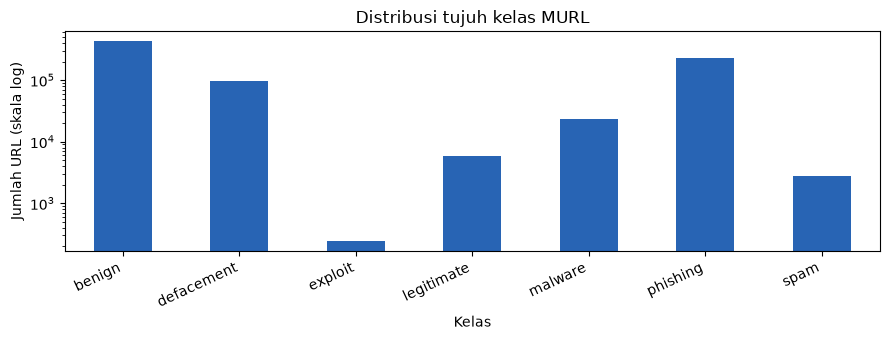

In [2]:
DATA_FILE = ROOT / "Malicious URL Detection.csv"
raw = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
assert raw.columns.tolist() == ["url", "type"] and len(raw) == 783705
df = pd.DataFrame({"row_id": np.arange(len(raw)), "url": raw.url.str.strip(),
                   "label": raw.type.str.strip().str.lower()})
assert df.url.ne("").all() and df.label.ne("").all()
assert sorted(df.label.unique()) == ["benign", "defacement", "exploit", "legitimate", "malware", "phishing", "spam"]
assert df.groupby("url")["label"].nunique().max() == 1, "Ada label bertentangan untuk URL yang sama."
print(f"Seluruh {len(df):,} baris dimuat; tidak ada penghapusan atau pengambilan sampel.")
print("URL dengan spasi ujung yang dibersihkan:", int((raw.url != df.url).sum()))
print("Salinan URL berulang yang tetap dipertahankan:", int(df.url.duplicated().sum()))
counts = df.label.value_counts().sort_index()
display(pd.DataFrame({"Jumlah": counts, "Persentase": counts / len(df) * 100}).round(3))
fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot.bar(ax=ax, logy=True, color="#2864b4")
ax.set(title="Distribusi tujuh kelas MURL", xlabel="Kelas", ylabel="Jumlah URL (skala log)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### 2.2 Pembagian data dan pemeriksaan kebocoran host

Semua **783.705 baris** dipertahankan, termasuk duplikat dan kelas langka. Pembagian terkunci `icann-domain-disjoint-v3`: **548.592 train**, **117.559 validation**, **117.554 test** (sekitar 70/15/15). Tujuh label tetap terpisah, termasuk `benign` dan `legitimate`; kelas `exploit` berjumlah 170/37/36 pada ketiga partisi.

Domain terdaftar beserta subdomainnya ditempatkan dalam satu partisi; alias IP dan hostname Unicode/punycode dikanonisasi untuk audit. Tidak ada irisan domain/IP, hostname kanonis, atau URL setelah strip antarpartisi. URL yang tidak memiliki identitas situs yang dapat dipastikan tetap dipertahankan dalam satu kelompok konservatif. Public Suffix List lokal digunakan secara tetap. Pembagian ditentukan dari jumlah baris, label, dan kelompok situs, tanpa melihat skor model.




**Penjelasan sel kode berikut:**


**Sel definisi pendukung di bawah:** menyertakan penugasan train/validation/test yang sudah dikunci, daftar sufiks publik, parser identitas situs, serta pemeriksaan overlap. Data pendukung dikemas agar tidak memerlukan file `.npz`, `.dat`, atau `.py` lain. Sumber sel dilipat karena memuat data pendukung; buka untuk memeriksa implementasinya. Ini belum menjalankan training maupun mengacak ulang split.


In [3]:
import base64
import io
import ipaddress
import re
import socket
import tempfile
from urllib.parse import urlsplit, unquote
import idna
import tldextract
VERSION = 'icann-domain-disjoint-v3'
ROLES = ('train', 'validation', 'test')
RATIOS = np.array([0.7, 0.15, 0.15])
MAX_OUTER_CLASS_ERROR = 0.005
MAX_TOTAL_ERROR = 0.001
SCHEME = re.compile('^(?:[A-Za-z][A-Za-z0-9+.-]*://|(?:mailto|data|javascript|tel|urn):)', re.I)
SPECIAL_SCHEME = re.compile('^(https?|ftp|ws|wss):[ \\t\\r\\n]*/*', re.I)
C0_SPACE = ''.join((chr(code) for code in range(33)))
NUMERIC_IP = re.compile('^(?:0x[0-9a-f]+|[0-9]+)(?:\\.(?:0x[0-9a-f]+|[0-9]+)){0,3}$', re.I)

def raw_hostname(value):
    value = value.replace('\\', '/').replace('\t', '').replace('\r', '').replace('\n', '').strip(C0_SPACE)
    match = SPECIAL_SCHEME.match(value)
    if match:
        value = match.group(1).lower() + '://' + value[match.end():]
    try:
        parsed = urlsplit(value if SCHEME.match(value) or value.startswith('//') else '//' + value)
        return (parsed.hostname or '').lower().rstrip('.')
    except ValueError:
        return ''

def host_site(host, extract):
    """ICANN eTLD+1 groups all subdomains/tenants; IP aliases use one literal key."""
    host = unquote(host).strip().lower().rstrip('.')
    if not host:
        return ('', 'unresolved-authority')
    try:
        canonical = idna.encode(host, uts46=True).decode('ascii').lower()
    except idna.IDNAError:
        canonical = host
    try:
        address = ipaddress.ip_address(canonical)
        if isinstance(address, ipaddress.IPv6Address) and address.ipv4_mapped is not None:
            address = address.ipv4_mapped
        return (str(address), 'ip:' + str(address))
    except ValueError:
        pass
    if NUMERIC_IP.fullmatch(canonical):
        try:
            address = str(ipaddress.IPv4Address(socket.inet_aton(canonical)))
            return (address, 'ip:' + address)
        except OSError:
            pass
    result = extract(canonical)
    root = result.top_domain_under_public_suffix or '.'.join(canonical.split('.')[-2:])
    try:
        root = idna.encode(root, uts46=True).decode('ascii').lower()
    except idna.IDNAError:
        return (canonical, 'unresolved-authority')
    return (canonical, 'domain:' + root)

def quality_report(urls, labels, hosts, site_ids, indices, classes):
    labels, urls = (np.asarray(labels), np.asarray(urls))
    total = pd.Series(labels).value_counts().reindex(classes).to_numpy()
    counts = np.array([pd.Series(labels[indices[role]]).value_counts().reindex(classes, fill_value=0).to_numpy() for role in ROLES])
    np.testing.assert_array_equal(np.sort(np.concatenate(list(indices.values()))), np.arange(len(urls)))
    assert (counts >= 30).all(), 'Setiap kelas harus terwakili dalam setiap partisi.'
    class_error = float(abs(counts / total - RATIOS[:, None]).max())
    total_error = float(abs(counts.sum(axis=1) / len(urls) - RATIOS).max())
    assert class_error <= MAX_OUTER_CLASS_ERROR and total_error <= MAX_TOTAL_ERROR
    overlap = {}
    for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        a, b = (indices[first], indices[second])
        item = {'site_groups': len(set(site_ids[a]) & set(site_ids[b])), 'hostnames': len(set(hosts[a]) - {''} & set(hosts[b]) - {''}), 'stripped_urls': len(set(urls[a]) & set(urls[b]))}
        assert not any(item.values()), (first, second, item)
        overlap[first + '_vs_' + second] = item
    domain_counts = np.array([[len(np.unique(site_ids[indices[role]][labels[indices[role]] == label])) for label in classes] for role in ROLES])
    assert (domain_counts >= 10).all()
    return {'version': VERSION, 'rows': len(urls), 'site_groups': int(len(np.unique(site_ids))), 'targets': dict(zip(ROLES, RATIOS.tolist())), 'outer_rows': {role: len(indices[role]) for role in ROLES}, 'class_counts': {label: {role: int(counts[i, j]) for i, role in enumerate(ROLES)} for j, label in enumerate(classes)}, 'class_site_counts': {label: {role: int(domain_counts[i, j]) for i, role in enumerate(ROLES)} for j, label in enumerate(classes)}, 'max_outer_class_allocation_error': class_error, 'max_outer_total_error': total_error, 'overlap': overlap}
_SPLIT_BUNDLE = '...'

def load_partitions(df):
    with np.load(io.BytesIO(base64.b64decode(_SPLIT_BUNDLE)), allow_pickle=False) as data:
        partition = data['partitions'].copy()
        psl_bytes = data['psl_utf8'].tobytes()
    assert len(partition) == len(df) == 783705
    assert set(np.unique(partition)) == {0, 1, 2}
    indices = {role: np.flatnonzero(partition == number) for number, role in enumerate(ROLES)}
    with tempfile.TemporaryDirectory(prefix='murl-psl-') as directory:
        psl_file = Path(directory) / 'public_suffix_list.dat'
        psl_file.write_bytes(psl_bytes)
        extract = tldextract.TLDExtract(suffix_list_urls=[psl_file.resolve().as_uri()], cache_dir=None, fallback_to_snapshot=False, include_psl_private_domains=False)
        raw_hosts = df.url.map(raw_hostname)
        lookup = {host: host_site(host, extract) for host in raw_hosts.unique()}
        hosts = raw_hosts.map(lambda host: lookup[host][0]).to_numpy()
        keys = raw_hosts.map(lambda host: lookup[host][1]).to_numpy()
    site_keys, site_ids = np.unique(keys, return_inverse=True)
    site_ids = site_ids.astype(np.int32)
    classes = sorted(df.label.unique())
    quality = quality_report(df.url.to_numpy(), df.label.to_numpy(), hosts, site_ids, indices, classes)
    quality['unresolved_rows'] = int(np.sum(keys == 'unresolved-authority'))
    return {'indices': indices, 'site_id': site_ids, 'site_keys': site_keys.tolist(), 'hosts': hosts, 'quality': quality, 'version': VERSION}


**Sel penerapan split:** jalankan fungsi yang baru didefinisikan pada seluruh URL. Kode memeriksa penugasan tiap baris, representasi semua kelas, dan tidak adanya irisan domain/IP, hostname, maupun URL. Tabel di bawah harus menunjukkan nol overlap. Penugasan yang disematkan sama pada seluruh notebook sehingga metode training menerima baris yang sama.


In [4]:
design = load_partitions(df)
df["site_id"] = design["site_id"]
df["partisi"] = ""
for role, ids in design["indices"].items():
    df.loc[ids, "partisi"] = role
np.testing.assert_array_equal(
    np.sort(np.concatenate(list(design["indices"].values()))), np.arange(len(df)))
split_counts = pd.crosstab(df.label, df.partisi).reindex(columns=["train", "validation", "test"])
assert (split_counts > 0).all().all() and split_counts.to_numpy().sum() == len(df)
display(split_counts.rename(columns={"train": "Latih", "validation": "Validation", "test": "Test"}))
display(pd.DataFrame(design["quality"]["overlap"]).T)


partisi,Latih,Validation,Test
label,,,
benign,298498,63965,63969
defacement,66674,14295,14294
exploit,170,37,36
legitimate,4066,871,872
malware,16517,3541,3534
phishing,160738,34438,34437
spam,1929,412,412


,site_groups,hostnames,stripped_urls
train_vs_validation,0,0,0
train_vs_test,0,0,0
validation_vs_test,0,0,0


### 2.3 Transformasi fitur — TF-IDF karakter

#### TF-IDF karakter: dari teks URL menjadi matriks angka

1. **Pertahankan teks URL** setelah membuang spasi di ujung. Huruf besar/kecil dipertahankan (`lowercase=False`) karena path/query dapat peka terhadap kapitalisasi. Tidak ada penghapusan stopword, pemotongan URL, atau decoding tambahan.
2. **Pecah menjadi karakter 3–5 gram** yang saling bertumpang tindih. Contoh `login`: 3-gram `log`, `ogi`, `gin`; 4-gram `logi`, `ogin`; 5-gram `login`. Angka dan tanda baca ikut menjadi pola. Rentang ini menggabungkan fragmen pendek dan konteks lebih panjang tanpa memerlukan batas kata.
3. **Pelajari kosakata dari data train saja.** `min_df=2` mengabaikan pola yang hanya muncul pada satu URL latih. `max_features=75000` membatasi kosakata pada paling banyak 75.000 pola berdasarkan frekuensi total dalam korpus latih. Ini batas jumlah kolom, **bukan batas jumlah URL**; seluruh baris tetap digunakan. Pola baru di validation/test yang tidak ada dalam kosakata diabaikan.
4. **Hitung bobot TF-IDF.** Frekuensi kemunculan diubah menjadi `1 + ln(tf)` (`sublinear_tf=True`). Dengan pemulusan bawaan, `idf = ln((1 + n) / (1 + df)) + 1`, dengan `n` jumlah dokumen latih dan `df` jumlah dokumen latih yang memuat pola. Bobot sebelum normalisasi adalah `tf × idf`.
5. **L2 normalization per URL** sehingga panjang vektor tak nol menjadi satu. Hasil berupa matriks sparse `float32`; nilai nol tidak disimpan satu per satu. TF-IDF tidak diteruskan ke StandardScaler.

**Mengapa 3–5 dan 75.000?** Keduanya diwarisi dari eksperimen SVM sebagai konfigurasi awal untuk menyeimbangkan pola yang ditangkap, memori, dan waktu komputasi. Angka ini **belum dibuktikan optimal**. N-gram lebih panjang memperluas kosakata dan dapat menghafal fragmen spesifik; batas fitur terlalu kecil dapat membuang pola kelas langka. Perbandingan model mempertahankan nilai ini supaya preprocessing tetap sama. Pencarian nilai terbaik harus memakai train/validation saja, kemudian dinilai pada holdout baru; jangan memilihnya dari skor test.

Referensi: [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).


**Penjelasan sel kode berikut:** factory membuat objek TF-IDF dengan konfigurasi bersama, lalu `build_analyzer` memperlihatkan contoh n-gram dari `login`. Objek ini belum di-fit dan belum mempunyai kosakata/IDF dari dataset. Fitting kosakata/IDF dilakukan hanya pada bagian fitting train penuh saat training final; validation/test memakai transformasi yang sudah dipelajari itu.

Objek pada sel ini adalah pratinjau konfigurasi. Saat training final, pipeline membuat objek baru melalui factory yang sama; statistik fitting hanya dipelajari dari train.

**Sel definisi fungsi:** menyediakan transformasi reusable di dalam notebook. Fungsi hanya membuat objek baru yang belum di-fit; statistik dataset belum dipelajari.


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer


def make_preprocessing(representation="tfidf"):
    if representation != "tfidf":
        raise ValueError("Notebook ini memakai TF-IDF.")
    return TfidfVectorizer(
        analyzer="char", ngram_range=(3, 5), lowercase=False,
        min_df=2, max_features=75000, sublinear_tf=True,
        norm="l2", dtype=np.float32,
    )


**Sel contoh penggunaan:** buat satu objek preprocessing, tampilkan konfigurasinya, dan amati contoh transformasi. Ini menunjukkan cara kerja fitur tanpa melakukan fitting pada seluruh dataset. model final akan membuat objek baru melalui fungsi yang sama.


In [6]:
REPRESENTATION = "tfidf"
preprocessing = make_preprocessing(REPRESENTATION)
print(preprocessing)
print("Contoh n-gram untuk login:", preprocessing.build_analyzer()("login"))
print("Kosakata dan IDF belum dipelajari; belum ada fit pada dataset penuh.")


TfidfVectorizer(analyzer='char', dtype=<class 'numpy.float32'>, lowercase=False,
                max_features=75000, min_df=2, ngram_range=(3, 5),
                sublinear_tf=True)
Contoh n-gram untuk login: ['log', 'ogi', 'gin', 'logi', 'ogin', 'login']
Kosakata dan IDF belum dipelajari; belum ada fit pada dataset penuh.


## 3. Metode training

SVM linear mempelajari batas pemisah pada ruang fitur. LinearSVC menangani tujuh kelas dengan satu kelas melawan kelas lainnya. `C=1` mengatur penalti kesalahan; class weight seimbang dipelajari hanya dari label fitting. Solver primal memakai `dual=False`, toleransi `1e-4`, batas 10.000 iterasi, dan seed 42. Peringatan konvergensi menghentikan proses.

Referensi: [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html).

Mulai bagian ini, metode boleh berbeda. Data, preprocessing, fold, dan evaluasi tetap sama. Parameter di bawah ditetapkan sebelum membaca skor validation/test; notebook tidak melakukan pencarian hyperparameter.


In [7]:
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

MODEL_FAMILY = 'svm'
SEED = 42
LABEL_MODEL = {MODEL_FAMILY: 'SVM linear'}


def make_classifier(family):
    if family != MODEL_FAMILY:
        raise ValueError("Pilih metode yang sesuai dengan notebook ini.")
    return LinearSVC(C=1.0, class_weight="balanced", dual=False,
                     tol=1e-4, max_iter=10000, random_state=SEED)


def kernel_settings(family):
    return None

display(pd.Series(make_classifier(MODEL_FAMILY).get_params(), name="Parameter metode").to_frame())
pemetaan_kernel = kernel_settings(MODEL_FAMILY)
if pemetaan_kernel is not None:
    display(pd.Series(pemetaan_kernel, name="Parameter pemetaan kernel").to_frame())


,Parameter metode
C,1.0
class_weight,balanced
dual,False
fit_intercept,True
intercept_scaling,1
loss,squared_hinge
max_iter,10000
multi_class,ovr
penalty,l2
random_state,42


**Sel fungsi training dan evaluasi bersama:** mendefinisikan pembuatan pipeline, fitting train, fitting model final, perhitungan metrik, gambar confusion matrix, penyimpanan prediksi, dan interpretasi. Isi sel ini identik pada seluruh notebook. Fungsi baru berjalan ketika dipanggil pada tahap berikutnya; tidak membaca kode lokal dari file lain.


In [8]:
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
import json
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
RESULTS = Path('results/hasil_model')
VERSIONS = versi
LABEL_REP = {'tfidf': 'TF-IDF karakter', 'feature_engineering': '54 fitur numerik URL'}

def make_model(family, representation):
    steps = [('preprocessing', make_preprocessing(representation))]
    mapping = kernel_settings(family)
    if mapping is not None:
        steps.append(('kernel_map', ClassBalancedNystroem(**mapping)))
    steps.append(('classifier', make_classifier(family)))
    return Pipeline(steps)

def fit_model(model, urls, labels):
    with warnings.catch_warnings(), threadpool_limits(limits=4):
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(urls, labels)
    classifier = model.named_steps['classifier']
    if isinstance(classifier, LinearSVC):
        assert classifier.n_iter_ < classifier.max_iter
    if 'kernel_map' in model.named_steps:
        mapper = model.named_steps['kernel_map']
        assert mapper.fit_input_rows_ == len(urls)
        assert len(set(mapper.landmark_indices_)) == mapper.n_components_
    return model

def save_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8')
    temporary.replace(path)

def metrics(truth, prediction, classes):
    return {'accuracy': float(accuracy_score(truth, prediction)), 'balanced_accuracy': float(balanced_accuracy_score(truth, prediction)), 'macro_f1': float(f1_score(truth, prediction, labels=classes, average='macro', zero_division=0)), 'weighted_f1': float(f1_score(truth, prediction, labels=classes, average='weighted', zero_division=0))}

def report_frame(report, classes):
    records = {label: report[label] for label in classes + ['macro avg', 'weighted avg']}
    frame = pd.DataFrame(records).T
    return frame.rename(columns={'precision': 'Precision', 'recall': 'Recall', 'f1-score': 'F1', 'support': 'Support'}, index={'macro avg': 'Macro average', 'weighted avg': 'Weighted average'})

def context(family, representation, df, design):
    return {'model': family, 'representation': representation, 'split_design_version': 'icann-domain-disjoint-v3', 'row_count': len(df), 'classes': sorted(df.label.unique()), 'seed': SEED, 'versions': VERSIONS, 'classifier_settings': make_classifier(family).get_params(), 'kernel_settings': kernel_settings(family), 'preprocessing': repr(make_preprocessing(representation)), 'split_counts': {role: int(len(ids)) for role, ids in design['indices'].items()}}

def fit_final(family, representation, df, design):
    """Fit preprocessing dan model pada seluruh train; validation/test dikecualikan."""
    meta = context(family, representation, df, design)
    save_json(RESULTS / f'{family}_{representation}_metrics.json', {**meta, 'completed': False, 'run_id': uuid4().hex})
    ids = design['indices']['train']
    model = make_model(family, representation)
    print(f'Melatih {LABEL_MODEL[family]} pada seluruh {len(ids):,} baris train...', flush=True)
    started = perf_counter()
    fit_model(model, df.url.iloc[ids], df.label.iloc[ids])
    seconds = perf_counter() - started
    assert model.named_steps['classifier'].classes_.tolist() == meta['classes']
    if representation == 'feature_engineering':
        assert model.named_steps['preprocessing'].named_steps['scaler'].n_samples_seen_ == len(ids)
    print(f"Selesai dalam {seconds:.1f} detik; jumlah fitur: {model.named_steps['classifier'].n_features_in_:,}.")
    return (model, seconds)

def evaluate(model, role, df, design):
    ids = design['indices'][role]
    truth = df.label.iloc[ids]
    classes = sorted(df.label.unique())
    started = perf_counter()
    prediction = model.predict(df.url.iloc[ids])
    seconds = perf_counter() - started
    score = metrics(truth, prediction, classes)
    report = classification_report(truth, prediction, labels=classes, output_dict=True, zero_division=0)
    cm = confusion_matrix(truth, prediction, labels=classes)
    assert cm.sum() == len(ids)
    title = 'Validation' if role == 'validation' else 'Test'
    print(f'{title}: {len(ids):,} baris; prediksi {seconds:.1f} detik.')
    display(pd.DataFrame([score], index=[title]).round(4))
    display(report_frame(report, classes).round(4))
    if role == 'test':
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        for ax, matrix, name, fmt in [(axes[0], cm, 'Jumlah prediksi', 'd'), (axes[1], cm / cm.sum(axis=1, keepdims=True), 'Recall per kelas', '.2f')]:
            ConfusionMatrixDisplay(matrix, display_labels=classes).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45, values_format=fmt)
            ax.set(title=f'Confusion matrix — {name}', xlabel='Predicted class', ylabel='Actual class')
        plt.tight_layout()
        plt.show()
        i = classes.index('exploit')
        print(f'Kelas exploit: {cm[i, i]}/{cm[i].sum()} terdeteksi. Perhatikan jumlah contoh yang kecil.')
    return {'metrics': score, 'report': report, 'confusion_matrix': cm.tolist(), 'predict_seconds': seconds, 'prediction': prediction}

def save_result(family, representation, model, fit_seconds, validation, test, df, design):
    meta = context(family, representation, df, design)
    key = f'{family}_{representation}'
    run_id = uuid4().hex
    files = {}
    for role, result in [('validation', validation), ('test', test)]:
        path = RESULTS / f'{key}_{role}_predictions.csv.gz'
        ids = design['indices'][role]
        pd.DataFrame({'row_id': ids, 'y_true': df.label.iloc[ids].to_numpy(), 'y_pred': result['prediction'], 'run_id': run_id}).to_csv(path, index=False, compression='gzip')
        files[role] = path.name
    summary = {**meta, 'completed': True, 'run_id': run_id, 'fit_seconds': fit_seconds, 'input_features': int(model.named_steps['classifier'].n_features_in_), 'validation': validation['metrics'], 'test': test['metrics'], 'validation_report': validation['report'], 'test_report': test['report'], 'test_confusion_matrix': test['confusion_matrix'], 'prediction_files': files, 'completed_at_utc': datetime.now(timezone.utc).isoformat()}
    save_json(RESULTS / f'{key}_metrics.json', summary)
    report_frame(test['report'], meta['classes']).to_csv(RESULTS / f'{key}_test_report.csv')
    return summary

def interpretation(summary):
    report, classes = (summary['test_report'], summary['classes'])
    weakest = min(classes, key=lambda label: report[label]['f1-score'])
    print(f"{LABEL_MODEL[summary['model']]} + {LABEL_REP[summary['representation']]}:")
    print(f"Accuracy test {summary['test']['accuracy']:.2%}; macro F1 {summary['test']['macro_f1']:.4f}.")
    print(f"Kelas dengan F1 terendah: {weakest} ({report[weakest]['f1-score']:.4f}).")
    print('Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi. Hasil berlaku pada protokol ini; data tidak memuat timestamp, source, atau campaign.')


## 4. Melatih model final pada seluruh train

Buat pipeline baru, lalu fit pada seluruh 548.592 baris train. Preprocessing dipelajari ulang dari train penuh. Validation dan test tetap dikecualikan.


In [9]:
model, fit_seconds = fit_final(MODEL_FAMILY, REPRESENTATION, df, design)


Melatih SVM linear pada seluruh 548,592 baris train...


Selesai dalam 121.5 detik; jumlah fitur: 75,000.


## 5. Evaluasi validation

Hitung accuracy, balanced accuracy, macro F1, weighted F1, serta precision/recall/F1 dan jumlah contoh per kelas. Hasil validation menjadi diagnosis; konfigurasi eksperimen tetap tidak diubah.


In [10]:
validation = evaluate(model, "validation", df, design)


Validation: 117,559 baris; prediksi 3.8 detik.


,accuracy,balanced_accuracy,macro_f1,weighted_f1
Validation,0.8634,0.6261,0.652,0.8648


,Precision,Recall,F1,Support
benign,0.8967,0.9065,0.9016,63965.0
defacement,0.9495,0.7634,0.8464,14295.0
exploit,0.8750,0.3784,0.5283,37.0
legitimate,0.2301,0.4569,0.3060,871.0
malware,0.9095,0.7944,0.8481,3541.0
phishing,0.8055,0.8501,0.8272,34438.0
spam,0.4465,0.2330,0.3062,412.0
Macro average,0.7304,0.6261,0.6520,117559.0
Weighted average,0.8703,0.8634,0.8648,117559.0


## 6. Evaluasi test

Gunakan partisi test yang sama pada seluruh notebook. Confusion matrix menempatkan kelas sebenarnya pada baris dan kelas prediksi pada kolom. Normalisasi baris menunjukkan recall. Perhatikan kelas langka: test hanya memuat 36 contoh exploit. Holdout sudah pernah dieksplorasi; ini evaluasi dalam dataset, bukan konfirmasi eksternal baru.


**Membaca classification report:** precision mengukur berapa banyak prediksi suatu kelas yang benar; recall mengukur berapa banyak contoh sebenarnya pada kelas itu yang terdeteksi. F1-score merangkum keduanya. Support adalah jumlah contoh sebenarnya pada kelas tersebut. Macro F1 memberi bobot sama pada setiap kelas; weighted F1 mengikuti support. Accuracy mengukur proporsi semua prediksi yang benar, sedangkan balanced accuracy merata-ratakan recall tiap kelas.


Test: 117,554 baris; prediksi 4.3 detik.


,accuracy,balanced_accuracy,macro_f1,weighted_f1
Test,0.8358,0.685,0.7064,0.8393


,Precision,Recall,F1,Support
benign,0.8927,0.8613,0.8767,63969.0
defacement,0.9574,0.7931,0.8675,14294.0
exploit,0.9600,0.6667,0.7869,36.0
legitimate,0.2072,0.4243,0.2784,872.0
malware,0.8219,0.6684,0.7372,3534.0
phishing,0.7395,0.8373,0.7854,34437.0
spam,0.7022,0.5437,0.6129,412.0
Macro average,0.7544,0.6850,0.7064,117554.0
Weighted average,0.8479,0.8358,0.8393,117554.0


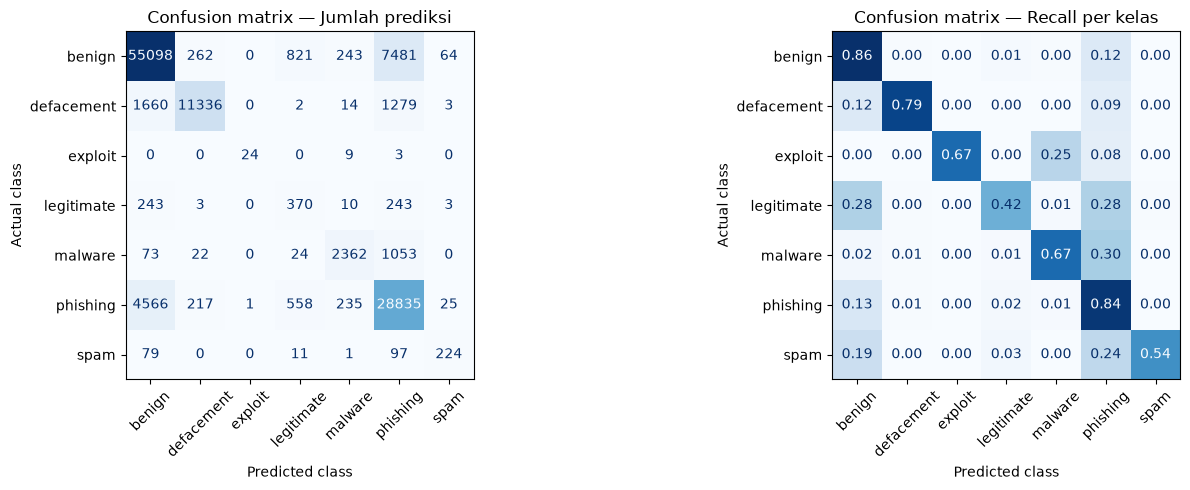

Kelas exploit: 24/36 terdeteksi. Perhatikan jumlah contoh yang kecil.


In [11]:
test = evaluate(model, "test", df, design)


## 7. Menyimpan hasil model ini

Hasil disimpan di `results/hasil_model/` dengan nama metode dan representasi: prediksi validation/test per baris, laporan per kelas, parameter, versi pustaka, jumlah baris per partisi, serta identitas baris. Status belum selesai diberi `completed: false`, bukan skor contoh. Tidak ada tabel perbandingan antarmodel.


**Penjelasan sel kode berikut:** `save_result` menyimpan hasil model final yang saling cocok, termasuk prediksi per baris untuk audit. `interpretation` menjelaskan skor aktual serta kelas dengan F1 terendah. Objek model kemudian dilepas dari memori; dataset dan file hasil tetap tersimpan.


In [12]:
summary = save_result(MODEL_FAMILY, REPRESENTATION, model, fit_seconds,
                      validation, test, df, design)
interpretation(summary)
del model, validation, test
gc.collect()


SVM linear + TF-IDF karakter:
Accuracy test 83.58%; macro F1 0.7064.
Kelas dengan F1 terendah: legitimate (0.2784).
Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi. Hasil berlaku pada protokol ini; data tidak memuat timestamp, source, atau campaign.


9979

## 8. Interpretasi dan batas kesimpulan

Utamakan **macro F1**, balanced accuracy, dan precision/recall/F1 setiap kelas. Accuracy tinggi dapat menyembunyikan kegagalan pada kelas langka. Macro F1 memberi bobot sama pada tujuh kelas; weighted F1 mengikuti jumlah contoh. Confusion matrix menampilkan kelas sebenarnya pada baris dan kelas prediksi pada kolom. Versi normalisasi baris memperlihatkan recall.



Hasil berlaku untuk protokol dan konfigurasi ini. Data sudah pernah dieksplorasi dan holdout dipakai bersama; hasil bukan konfirmasi eksternal baru. Domain yang berbeda masih mungkin berasal dari kampanye, templat, atau sumber koleksi yang sama. CSV tidak memuat waktu/sumber/kampanye sehingga belum membuktikan kemampuan mendeteksi ancaman masa depan. Jangan mengubah split atau parameter berdasarkan skor test.

Hasil notebook ini dicatat bersama konfigurasi dan identitas datanya agar dapat diaudit. Riwayat eksperimen tetap disimpan terpisah.
